# 01 · Regresión multisalida con un perceptrón multicapa

**Curso:** Fundamentos de Programación para la Inteligencia Artificial · **Autor:** William Lu Bjornestad

---

En este primer cuaderno se entrena una red neuronal totalmente conectada (MLP) que aproxima **tres funciones reales a la vez** a partir de una única variable de entrada. Es el punto de partida del curso: aquí se construyen las piezas básicas (datos sintéticos, `Dataset`, `DataLoader`, bucle de entrenamiento y validación) que se reutilizan y amplían en el resto de cuadernos.

**Objetivos**

- Ajustar simultáneamente $f_1$, $f_2$ y $f_3$ en el rango $x \in [-120, 120]$.
- Trabajar con tres particiones: entrenamiento (con ruido gaussiano $\mathcal{N}(0, 5^2)$), validación (500 ejemplos) y test (500 ejemplos).
- Utilizar `TensorDataset` y `DataLoader` de PyTorch.

**Conceptos de pipeline de ML introducidos**

| Etapa | Qué se ve en este cuaderno |
|---|---|
| Reproducibilidad | Semillas fijas para datos y pesos |
| Partición de datos | Train / validación / test con papeles distintos |
| Preprocesado | Estandarización ajustada **solo** con train (evitar *data leakage*) |
| Selección de modelo | Guardar los pesos con menor error de validación (*checkpointing*) |
| Evaluación | Métrica final en test, en las unidades originales del problema |

In [1]:
import copy
import time

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# La red es diminuta: el coste de lanzar kernels en GPU supera al cálculo, así que la CPU es más rápida aquí.
device = torch.device("cpu")

## 1. Definición del problema

Las funciones objetivo son:

$$f_1(x) = \log\left(10x^4 + x^2\right) - \frac{2x}{5}, \qquad f_2(x) = \frac{x^2}{140} + x - 2^{x/15}, \qquad f_3(x) = 10\,\frac{3e^{2x} - 2}{2e^{2x} + e^{x} + 3}$$

Dos detalles numéricos:

- En $f_1$ se suma un $\varepsilon = 10^{-6}$ dentro del logaritmo para evitar $\log(0)$ en $x = 0$.
- En $f_3$, $e^{2x}$ desborda en `float32` para $x \gtrsim 44$. Para $x \ge 0$ se multiplica numerador y denominador por $e^{-2x}$, de modo que solo aparecen exponenciales negativas; para $x < 0$ se usa la forma original. Ambas expresiones son algebraicamente equivalentes.

In [2]:
X_RANGE = 120.0


def f1(x):
    eps = 1e-6
    return torch.log(10 * x**4 + x**2 + eps) - (2 * x) / 5


def f2(x):
    return (x**2) / 140 + x - 2 ** (x / 15)


def f3(x):
    # Versión numéricamente estable: solo se evalúan exponenciales que no desbordan
    y_pos = 10 * (3 - 2 * torch.exp(-2 * x)) / (2 + torch.exp(-x) + 3 * torch.exp(-2 * x))
    y_neg = 10 * (3 * torch.exp(2 * x) - 2) / (2 * torch.exp(2 * x) + torch.exp(x) + 3)
    return torch.where(x >= 0, y_pos, y_neg)


def target(x):
    return torch.stack([f1(x), f2(x), f3(x)], dim=1)


def sample_xy(n, generator):
    x = torch.rand(n, generator=generator) * 2 * X_RANGE - X_RANGE   # U(-120, 120)
    return x.unsqueeze(1), target(x)

## 2. Generación de datos y partición

Solo el conjunto de **entrenamiento** lleva ruido: simula mediciones imperfectas. Validación y test se generan sin ruido, por lo que miden la fidelidad del modelo a la función real, que es lo que interesa.

Esta decisión tiene una consecuencia importante al leer las curvas de error: si el ruido es $\varepsilon \sim \mathcal{N}(0, \sigma^2)$, incluso un modelo perfecto tendría en entrenamiento un error L1 esperado de

$$\mathbb{E}|\varepsilon| = \sigma\sqrt{2/\pi} \approx 0.798\,\sigma \approx 3.99 \quad (\sigma = 5).$$

Es decir, **el error de entrenamiento tiene un suelo cercano a 4**, mientras que el de validación puede bajar mucho más.

In [3]:
N_TRAIN, N_VAL, N_TEST = 5000, 500, 500
NOISE_STD = 5.0
BATCH_SIZE = 64

gen = torch.Generator().manual_seed(SEED)
x_train, y_train_clean = sample_xy(N_TRAIN, gen)
x_val, y_val = sample_xy(N_VAL, gen)
x_test, y_test = sample_xy(N_TEST, gen)

y_train = y_train_clean + NOISE_STD * torch.randn(y_train_clean.shape, generator=gen)

noise_floor = NOISE_STD * np.sqrt(2 / np.pi)
print(f"Suelo teórico del error L1 en entrenamiento: {noise_floor:.2f}")
print(f"Tamaños -> train: {len(x_train)}, val: {len(x_val)}, test: {len(x_test)}")

Suelo teórico del error L1 en entrenamiento: 3.99
Tamaños -> train: 5000, val: 500, test: 500


## 3. Bucle de entrenamiento con validación

El bucle alterna, en cada época, una fase de entrenamiento (`model.train()`, cálculo de gradientes y actualización de pesos) y una fase de validación (`model.eval()` y `torch.no_grad()`, sin actualizar nada).

Además de registrar las pérdidas, guarda una copia de los pesos de la época con **menor error de validación**. Este *checkpointing* permite recuperar el mejor modelo aunque el entrenamiento continúe después de ese punto, y es la base del *early stopping* que se introduce en el cuaderno 03.

Las pérdidas por época se promedian ponderando por el tamaño de cada lote, de forma que el último lote (normalmente más pequeño) no distorsiona la media.

In [4]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    # Con optimizer entrena; sin él, solo evalúa
    training = optimizer is not None
    model.train(training)
    total = 0.0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * xb.size(0)
    return total / len(loader.dataset)


def train_model(model, train_loader, val_loader, loss_fn, optimizer, epochs, log_every=500):
    history = {"train": [], "val": []}
    best_val, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(1, epochs + 1):
        history["train"].append(run_epoch(model, train_loader, loss_fn, optimizer))
        history["val"].append(run_epoch(model, val_loader, loss_fn))
        if history["val"][-1] < best_val:
            best_val, best_epoch = history["val"][-1], epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch == 1 or epoch % log_every == 0:
            print(f"Época {epoch:>5}/{epochs} | train {history['train'][-1]:.4f} | val {history['val'][-1]:.4f}")
    print(f"Mejor época: {best_epoch} (val = {best_val:.4f})")
    return history, best_state


def make_mlp(hidden=12):
    return nn.Sequential(
        nn.Linear(1, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden), nn.ReLU(),
        nn.Linear(hidden, 3),
    )

## 4. Modelo base: datos en bruto y SGD

La primera versión usa los datos tal cual, un MLP de 3 capas ocultas con 12 neuronas y activación ReLU (frente a `tanh` y `LeakyReLU`, fue la que mejor resultado dio en pruebas preliminares), pérdida L1 y descenso de gradiente estocástico.

In [5]:
EPOCHS_BASE = 3000
LR_BASE = 1e-3

train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=BATCH_SIZE)

torch.manual_seed(SEED)
model_base = make_mlp()
start = time.time()
hist_base, _ = train_model(
    model_base, train_loader, val_loader,
    loss_fn=nn.L1Loss(),
    optimizer=torch.optim.SGD(model_base.parameters(), lr=LR_BASE),
    epochs=EPOCHS_BASE,
)
print(f"Tiempo de entrenamiento: {time.time() - start:.1f} s")

Época     1/3000 | train 21.7119 | val 17.6773


Época   500/3000 | train 6.1792 | val 6.3193


Época  1000/3000 | train 5.5063 | val 4.0272


Época  1500/3000 | train 4.9717 | val 3.7628


Época  2000/3000 | train 4.9116 | val 4.0466


Época  2500/3000 | train 4.7339 | val 1.9556


Época  3000/3000 | train 4.7404 | val 3.3739
Mejor época: 2564 (val = 1.0750)
Tiempo de entrenamiento: 613.9 s


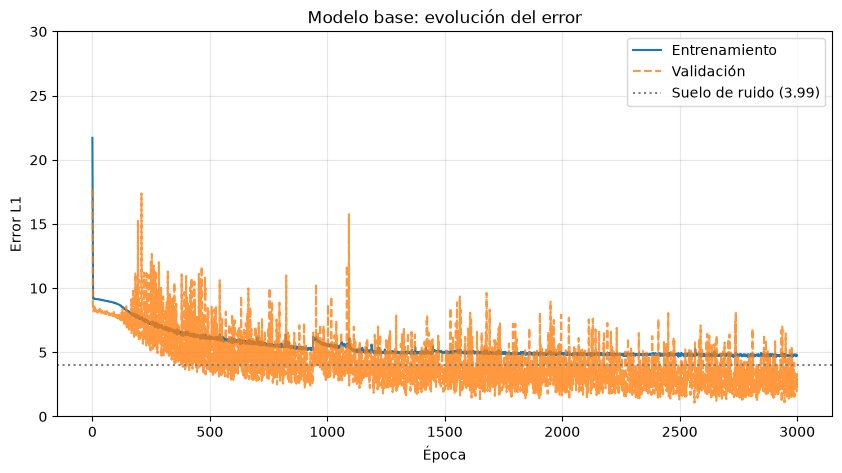

In [6]:
def plot_history(history, title, floor=None, ylim=None):
    plt.figure(figsize=(10, 5))
    plt.plot(history["train"], label="Entrenamiento")
    plt.plot(history["val"], label="Validación", linestyle="--", alpha=0.8)
    if floor is not None:
        plt.axhline(floor, color="grey", linestyle=":", label=f"Suelo de ruido ({floor:.2f})")
    plt.title(title)
    plt.xlabel("Época")
    plt.ylabel("Error L1")
    if ylim:
        plt.ylim(*ylim)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


plot_history(hist_base, "Modelo base: evolución del error", floor=noise_floor, ylim=(0, 30))

### Interpretación de las curvas

- **La validación queda por debajo del entrenamiento y eso no es sobreajuste.** Es la consecuencia directa del suelo de ruido calculado antes: el error de entrenamiento se estanca cerca de $\sigma\sqrt{2/\pi} \approx 4$ porque se mide contra etiquetas ruidosas, mientras que validación se mide contra la función limpia. El sobreajuste se reconocería por un error de validación que **sube** mientras el de entrenamiento sigue bajando, y eso no ocurre.
- **La validación oscila con fuerza.** La entrada vive en $[-120, 120]$ sin normalizar: las preactivaciones de la primera capa son grandes y pequeños cambios en los pesos provocan grandes cambios en la salida. Con SGD y una tasa de aprendizaje fija, el modelo "rebota" alrededor del mínimo. Es un problema de **condicionamiento numérico**, no de capacidad.
- La convergencia es lenta: hacen falta cientos de épocas para abandonar la meseta inicial (≈ 8-9).

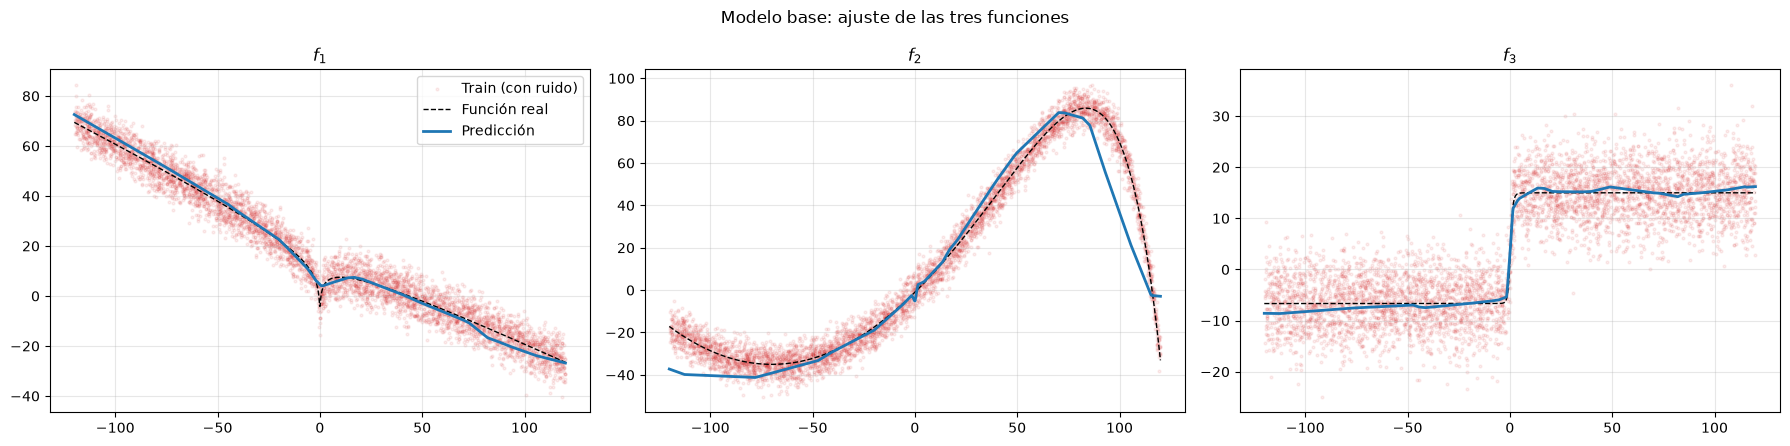

In [7]:
def predict(model, x, x_scaler=None, y_scaler=None):
    model.eval()
    with torch.no_grad():
        xin = x_scaler.transform(x) if x_scaler else x
        y = model(xin)
        return y_scaler.inverse_transform(y) if y_scaler else y


def plot_fits(model, title, x_scaler=None, y_scaler=None):
    x_plot = torch.linspace(-X_RANGE, X_RANGE, 1000).unsqueeze(1)
    y_true = target(x_plot.squeeze(1))
    y_pred = predict(model, x_plot, x_scaler, y_scaler)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for i, ax in enumerate(axes):
        ax.scatter(x_train, y_train[:, i], s=4, c="tab:red", alpha=0.08, label="Train (con ruido)")
        ax.plot(x_plot, y_true[:, i], c="black", lw=1, linestyle="--", label="Función real")
        ax.plot(x_plot, y_pred[:, i], c="tab:blue", lw=2, label="Predicción")
        ax.set_title(f"$f_{i + 1}$")
        ax.grid(True, alpha=0.3)
    axes[0].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_fits(model_base, "Modelo base: ajuste de las tres funciones")

## 5. Pipeline mejorado: estandarización

La forma habitual de corregir el mal condicionamiento es **estandarizar** entradas y salidas: restar la media y dividir por la desviación típica de cada columna, $z = (x - \mu)/\sigma$, igual que hace `StandardScaler` de scikit-learn.

La regla clave del pipeline es que $\mu$ y $\sigma$ se calculan **solo con el conjunto de entrenamiento** y después se aplican, sin recalcular, a validación y test. Si se usaran estadísticas de validación o test, información de esos conjuntos se filtraría al entrenamiento (*data leakage*) y la evaluación sería optimista.

Estandarizar las salidas también equilibra las tres tareas: sin ello, la función con mayor rango domina la pérdida L1 conjunta. Las predicciones se devuelven a unidades originales con la transformación inversa para que las métricas finales sean comparables.

In [8]:
class Standardizer:
    # Equivalente mínimo a sklearn.preprocessing.StandardScaler para tensores
    def fit(self, t):
        self.mean = t.mean(dim=0, keepdim=True)
        self.std = t.std(dim=0, keepdim=True)
        return self

    def transform(self, t):
        return (t - self.mean) / self.std

    def inverse_transform(self, t):
        return t * self.std + self.mean


x_scaler = Standardizer().fit(x_train)
y_scaler = Standardizer().fit(y_train)

print("Media / desviación de x (train):", x_scaler.mean.item(), x_scaler.std.item())
print("Desviación de cada salida (train):", y_scaler.std.squeeze().tolist())

train_loader_std = DataLoader(
    TensorDataset(x_scaler.transform(x_train), y_scaler.transform(y_train)), batch_size=BATCH_SIZE, shuffle=True
)
val_loader_std = DataLoader(TensorDataset(x_scaler.transform(x_val), y_scaler.transform(y_val)), batch_size=BATCH_SIZE)

Media / desviación de x (train): -0.7457128763198853 68.96955108642578
Desviación de cada salida (train): [28.320064544677734, 43.460243225097656, 11.882318496704102]


Se mantiene **exactamente la misma arquitectura** para aislar el efecto del preprocesado. Solo se cambia el optimizador por Adam, que adapta la tasa de aprendizaje de cada parámetro y suele converger más rápido que SGD. Se entrena menos épocas y, al final, se recuperan los pesos de la mejor época de validación.

In [9]:
EPOCHS_STD = 1000

torch.manual_seed(SEED)
model_std = make_mlp()
start = time.time()
hist_std, best_state = train_model(
    model_std, train_loader_std, val_loader_std,
    loss_fn=nn.L1Loss(),
    optimizer=torch.optim.Adam(model_std.parameters(), lr=1e-3),
    epochs=EPOCHS_STD,
    log_every=200,
)
model_std.load_state_dict(best_state)
print(f"Tiempo de entrenamiento: {time.time() - start:.1f} s")

Época     1/1000 | train 0.8171 | val 0.6662


Época   200/1000 | train 0.1945 | val 0.0309


Época   400/1000 | train 0.1934 | val 0.0256


Época   600/1000 | train 0.1924 | val 0.0210


Época   800/1000 | train 0.1920 | val 0.0278


Época  1000/1000 | train 0.1921 | val 0.0239
Mejor época: 967 (val = 0.0182)
Tiempo de entrenamiento: 202.0 s


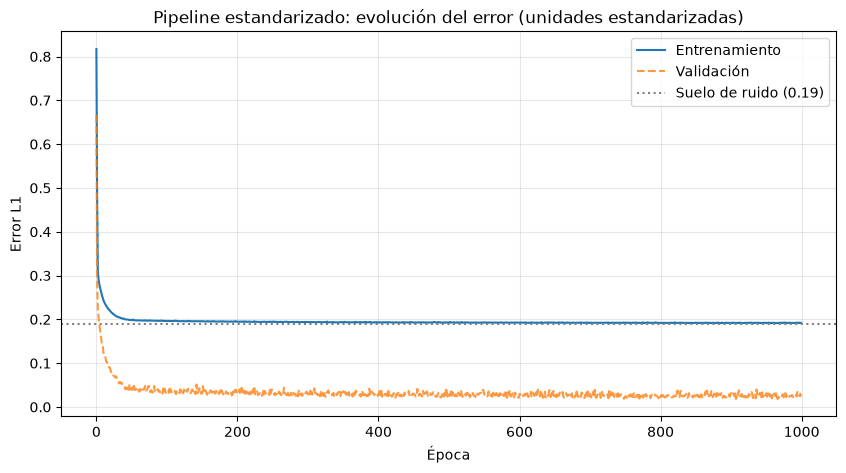

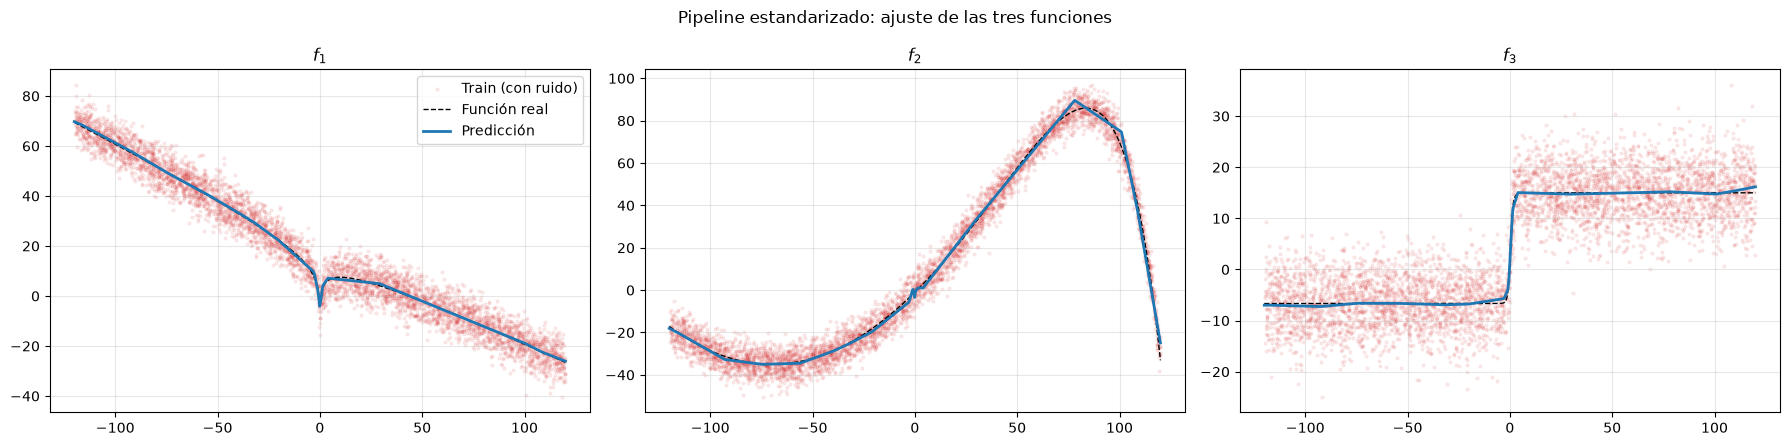

In [10]:
# En unidades estandarizadas el suelo de ruido es distinto para cada salida; se muestra la media
floor_std = (noise_floor / y_scaler.std).mean().item()
plot_history(hist_std, "Pipeline estandarizado: evolución del error (unidades estandarizadas)", floor=floor_std)
plot_fits(model_std, "Pipeline estandarizado: ajuste de las tres funciones", x_scaler, y_scaler)

## 6. Evaluación final en test

El conjunto de test solo se usa aquí, una vez tomadas todas las decisiones. El error se calcula en las unidades originales de cada función.

In [11]:
def test_mae(model, x_scaler=None, y_scaler=None):
    y_pred = predict(model, x_test, x_scaler, y_scaler)
    return (y_pred - y_test).abs().mean(dim=0)


mae_base = test_mae(model_base)
mae_std = test_mae(model_std, x_scaler, y_scaler)

print(f"{'':>22}{'f1':>8}{'f2':>8}{'f3':>8}{'media':>9}")
for name, mae in [("Base (bruto + SGD)", mae_base), ("Estandarizado + Adam", mae_std)]:
    print(f"{name:>22}" + "".join(f"{v:8.3f}" for v in mae.tolist()) + f"{mae.mean().item():9.3f}")

                            f1      f2      f3    media
    Base (bruto + SGD)   1.530   7.876   0.655    3.353
  Estandarizado + Adam   0.321   1.128   0.232    0.560


## 7. Análisis del error y límites del modelo

Un error medio resume, pero no explica. Representar el error absoluto frente a $x$ muestra **dónde** falla el modelo.

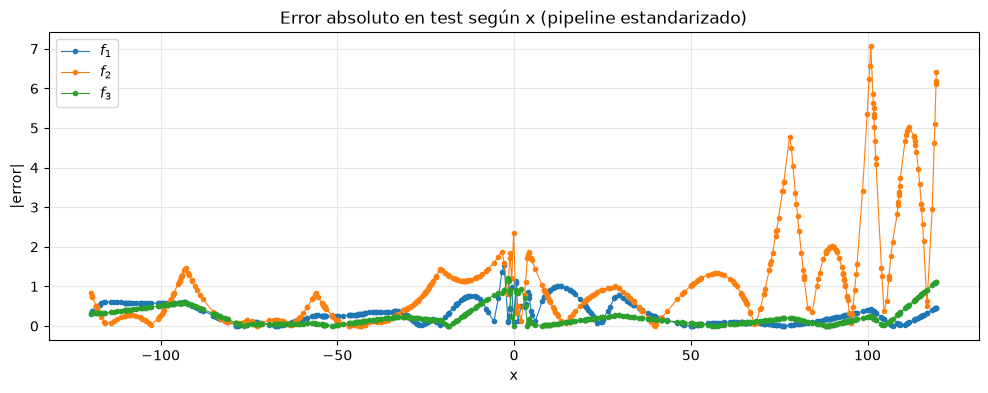

In [12]:
x_sorted, order = x_test.squeeze(1).sort()
abs_err = (predict(model_std, x_test, x_scaler, y_scaler) - y_test).abs()[order]

plt.figure(figsize=(12, 4))
for i in range(3):
    plt.plot(x_sorted, abs_err[:, i], marker=".", lw=0.8, label=f"$f_{i + 1}$")
plt.title("Error absoluto en test según x (pipeline estandarizado)")
plt.xlabel("x")
plt.ylabel("|error|")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Otra propiedad importante de un MLP con ReLU es cómo se comporta **fuera del rango de entrenamiento**. La red es una función lineal a trozos, de modo que más allá de los datos solo puede prolongar su último tramo como una recta.

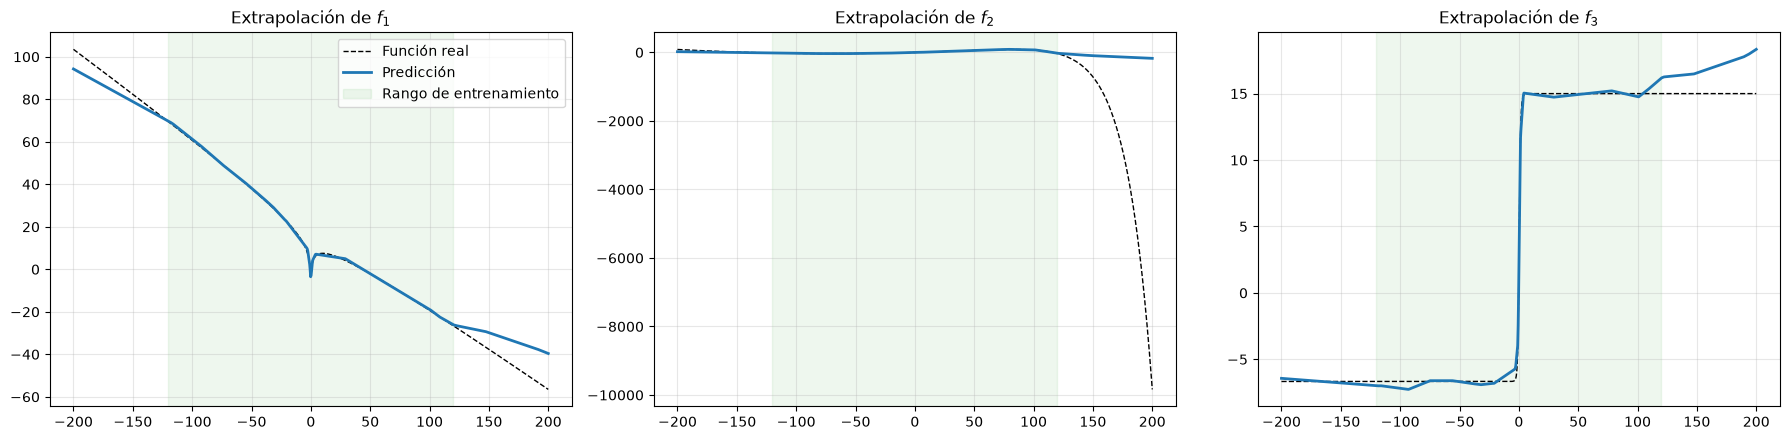

In [13]:
x_ext = torch.linspace(-200, 200, 1000).unsqueeze(1)
y_ext_true = target(x_ext.squeeze(1))
y_ext_pred = predict(model_std, x_ext, x_scaler, y_scaler)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for i, ax in enumerate(axes):
    ax.plot(x_ext, y_ext_true[:, i], "k--", lw=1, label="Función real")
    ax.plot(x_ext, y_ext_pred[:, i], c="tab:blue", lw=2, label="Predicción")
    ax.axvspan(-X_RANGE, X_RANGE, color="tab:green", alpha=0.08, label="Rango de entrenamiento")
    ax.set_title(f"Extrapolación de $f_{i + 1}$")
    ax.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

## 8. Conclusiones

- **Leer las curvas en su contexto.** Con etiquetas de entrenamiento ruidosas y validación limpia, que la validación quede por debajo es lo esperado. El suelo $\sigma\sqrt{2/\pi}$ da una referencia cuantitativa de hasta dónde puede bajar el error de entrenamiento.
- **El preprocesado importa tanto como el modelo.** Con la misma arquitectura, estandarizar entradas y salidas elimina las oscilaciones de validación, acelera la convergencia y reduce el error en test. Las estadísticas se ajustan solo con train y se reutilizan después: es el primer ejemplo de una etapa de pipeline con estado (*fit* / *transform*).
- **El modelo extrae toda la señal disponible.** La pérdida de entrenamiento estandarizada se asienta exactamente sobre el suelo de ruido: lo que queda por encima de él en entrenamiento es ruido irreducible, no falta de ajuste.
- **El error se concentra donde la función es difícil.** El mayor error en test aparece en $f_2$ para $x \gtrsim 75$, donde el término $-2^{x/15}$ domina y la curva pasa de su máximo a una caída casi vertical. Un MLP con ReLU aproxima esa curvatura con pocos tramos rectos. Los picos menores cerca de $x = 0$ corresponden al pozo logarítmico de $f_1$ y al salto de $f_3$, zonas muy estrechas con pocas muestras. Más neuronas, más muestras en esas regiones o una pérdida ponderada las mejorarían.
- **Un MLP interpola, no descubre la fórmula.** Fuera de $[-120, 120]$ la predicción continúa de forma lineal: no sigue el crecimiento exponencial de $f_2$ ni el logarítmico de $f_1$. Un modelo solo es fiable dentro de la distribución con la que se entrenó.

**Siguiente paso:** en el cuaderno 02 la entrada pasa de 1 a 2 dimensiones (coordenadas de una imagen) y se estudia cómo la *representación* de la entrada, no solo el modelo, determina qué funciones puede aprender una red.